# Part B — 2025 Staffing Model for Boston 311 Field Crews


**Question:** how many field crews should each of the four departments (PWDx, BTDT, PARK, ISD) run in each month of 2025, and when should we hire, release, or sign seasonal crews?

**Inputs:** `forecast_2025.csv` and `monthly_demand.csv` from Part A (data & forecast).
**Outputs:** `staffing_plan_2025.csv` (month × department plan), `plan_comparison.csv`, `sensitivity_results.csv`.

AI use: Model code and charts were drafted with Claude, then reviewed and validated in Colab by the author.

## 1. Setup and data

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Works in Colab (shared Drive folder) and locally (files next to the notebook)
DRIVE_DIR = "/content/drive/MyDrive/IE5374Project/Data/"
DATA_DIR = "./"
try:
    from google.colab import drive
    drive.mount("/content/drive")
    if os.path.exists(os.path.join(DRIVE_DIR, "forecast_2025.csv")):
        DATA_DIR = DRIVE_DIR
    else:
        print("Drive mounted, but the Data folder wasn't found. Add a shortcut to IE5374Project in My Drive, "
              "or upload the two CSVs to the Colab Files panel.")
except ImportError:
    pass  # not in Colab: read files next to the notebook
except Exception as e:
    print("Drive mount failed:", e, "-> reading CSVs uploaded to the Colab Files panel instead")
print("Reading data from and saving results to:", os.path.abspath(DATA_DIR))

hist = pd.read_csv(os.path.join(DATA_DIR, "monthly_demand.csv"))
fc = pd.read_csv(os.path.join(DATA_DIR, "forecast_2025.csv"))
pd.set_option("display.width", 160)
fc.pivot(index="month", columns="department", values="forecast_requests")

Mounted at /content/drive
Reading data from and saving results to: /content/drive/MyDrive/IE5374Project/Data


department,BTDT,ISD,PARK,PWDx
month,,,,
1,6365,1457,932,11684
2,6325,1608,795,9537
3,7923,1345,1209,11272
4,7378,1362,1499,11936
5,7998,1531,2278,12596
6,7784,1824,2858,12269
7,6834,1761,2721,13254
8,7415,1978,2503,16104
9,8328,1816,1721,15184


## 2. Assumptions

| Item | Value | Source |
|---|---|---|
| Crew capacity (requests/day) | PWDx 12 · BTDT 15 · PARK 6 · ISD 4 | Brief |
| Working days per month | 21 | Brief |
| Annual cost per crew | PWDx \$130k · BTDT \$110k · PARK \$120k · ISD \$140k | Brief |
| Crews in Jan 2025 | PWDx 50 · BTDT 18 · PARK 10 · ISD 16 | Brief |
| New crew | 1 month hiring/training before first shift; we pay that month | Brief + our assumption (paid training) |
| Release | 1 month notice, fee = 25% of annual cost | Brief |
| Parks seasonal crew | Apr–Oct, 1.3× monthly cost, no training, no release fee | Brief |
| Overdue request | \$20; extra \$100 (once) if still open 30+ days after target | Brief |
| Starting backlog | 0 on 1 Jan 2025 | Brief |
| January 2025 | crews fixed at the given level (any hire/release decision takes effect from February) | Our assumption |
| When is a request late? | a request not closed in the month it arrives misses its target; one still open at the end of the following month is 30+ days late | Our assumption (most 311 targets are days to a few weeks) |
| Order of work | oldest requests first (FIFO) | Our assumption |
| Requests without a target date (~16%) | still take crew time; treated like other requests | Our assumption |

The model is **monthly**: capacity = (full-time + seasonal crews) × daily capacity × 21. Requests that don't fit roll into next month's backlog.

## 3. Model
A FIFO backlog simulation (to evaluate any plan) and a mixed-integer program (to find the cheapest plan). Uses only `numpy`, `pandas` and `scipy`, so it runs in Colab without extra installs.

In [2]:
# Part B model — AI-assisted (Claude), reviewed by the team
import numpy as np, pandas as pd
from scipy.optimize import milp, LinearConstraint, Bounds

DEPTS = ["PWDx", "BTDT", "PARK", "ISD"]
PARAMS = pd.DataFrame({
    "dept": DEPTS,
    "daily_cap": [12, 15, 6, 4],                # requests per crew per day (brief)
    "annual_cost": [130_000, 110_000, 120_000, 140_000],
    "crews_jan": [50, 18, 10, 16],              # crews in January 2025 (brief)
}).set_index("dept")
WORK_DAYS = 21
OVERDUE_COST = 20       # each request that misses its target
LATE30_COST = 100       # extra, once, if still open 30+ days after target
RELEASE_FRAC = 0.25     # release cost = 25% of annual crew cost
SEASONAL_MULT = 1.3     # Parks seasonal crew: 1.3x monthly cost, no training, no release cost
SEASON_MONTHS = range(4, 11)  # April-October


def monthly_capacity(dept):
    return PARAMS.loc[dept].daily_cap * WORK_DAYS


def simulate(demand, crews, dept, seasonal=None):
    """Monthly first-in-first-out backlog simulation for one department.
    Assumptions: no backlog at the start of 2025; a request not closed in the month it
    arrives misses its target (overdue, $20); one still open at the end of the next month
    is 30+ days past target ($100, charged once)."""
    demand = np.asarray(demand, float)
    crews = np.asarray(crews, float)
    seasonal = np.zeros(12) if seasonal is None else np.asarray(seasonal, float)
    mcap = monthly_capacity(dept)
    cohorts = []            # [arrival_month, open_requests], oldest first
    rows = []
    for t in range(12):
        cap = (crews[t] + seasonal[t]) * mcap
        cohorts.append([t, demand[t]])
        left = cap
        for c in cohorts:                          # serve oldest first
            take = min(c[1], left); c[1] -= take; left -= take
        served = cap - left
        cohorts = [c for c in cohorts if c[1] > 1e-9]
        overdue = sum(c[1] for c in cohorts if c[0] == t)        # this month's arrivals left open
        late30 = sum(c[1] for c in cohorts if c[0] == t - 1)     # last month's arrivals still open
        backlog = sum(c[1] for c in cohorts)
        rows.append(dict(month=t + 1, demand=demand[t], crews=crews[t], seasonal=seasonal[t],
                         capacity=cap, served=served, backlog=backlog, overdue=overdue,
                         late30=late30, on_time_rate=1 - overdue / demand[t],
                         utilization=served / cap if cap else 0.0))
    return pd.DataFrame(rows)


def plan_cost(sim, dept, hires, releases):
    """hires[t]: crews that start working in month t (paid one training month before).
    releases[t]: crews gone from month t (notice given in month t-1, release fee 25%)."""
    p = PARAMS.loc[dept]
    m = p.annual_cost / 12
    out = dict(
        crew_cost=(sim.crews.sum() + np.sum(hires)) * m,
        seasonal_cost=sim.seasonal.sum() * m * SEASONAL_MULT,
        release_cost=np.sum(releases) * p.annual_cost * RELEASE_FRAC,
        overdue_cost=sim.overdue.sum() * OVERDUE_COST + sim.late30.sum() * LATE30_COST,
    )
    out["total"] = sum(out.values())
    return out


def optimize(demand, dept, min_on_time=None, allow_seasonal=None, allow_release=True, n_max=None):
    """Mixed-integer program for one department's 2025 plan.
    Decision per month t: n (active full-time crews), h (crews starting), r (crews released),
    s (Parks seasonal crews, Apr-Oct). Helper: served, B (open backlog), O (backlog older than
    one month). Objective = crew + training + release + seasonal + overdue costs.
    In the optimiser the $100 late charge is applied to every month a request stays 30+ days late
    (a slightly conservative stand-in that keeps the model linear); reported costs come from
    simulate(), which charges it once as the brief says. Plans with a service target keep that
    backlog near zero, so the two agree.
    min_on_time: optional monthly service target (share of each month's requests closed that month),
    applied Feb-Dec because January's crews are already fixed."""
    p = PARAMS.loc[dept]
    m = p.annual_cost / 12
    mcap = monthly_capacity(dept)
    demand = np.asarray(demand, float)
    T = 12
    if allow_seasonal is None:
        allow_seasonal = dept == "PARK"
    n_max = n_max or int(p.crews_jan * 2 + 10)
    names = ["n", "h", "r", "s", "srv", "B", "O"]
    idx = {k: np.arange(T) + i * T for i, k in enumerate(names)}
    N = len(names) * T

    c = np.zeros(N)
    c[idx["n"]] = m
    c[idx["h"]] = m                               # paid training month
    c[idx["r"]] = p.annual_cost * RELEASE_FRAC
    c[idx["s"]] = m * SEASONAL_MULT
    c[idx["B"]] = OVERDUE_COST                    # newly late (B - O) at $20 ...
    c[idx["O"]] = LATE30_COST - OVERDUE_COST      # ... and old backlog O at $100
    c[idx["srv"]] = -1e-3                         # tie-break: serve whenever capacity allows

    A, lo, hi = [], [], []
    for t in range(T):
        a = np.zeros(N); a[idx["n"][t]] = 1; a[idx["h"][t]] = -1; a[idx["r"][t]] = 1
        if t == 0:
            A.append(a); lo.append(p.crews_jan); hi.append(p.crews_jan)
        else:
            a[idx["n"][t - 1]] = -1; A.append(a); lo.append(0); hi.append(0)
        a = np.zeros(N); a[idx["B"][t]] = 1; a[idx["srv"][t]] = 1
        if t > 0: a[idx["B"][t - 1]] = -1
        A.append(a); lo.append(demand[t]); hi.append(demand[t])
        a = np.zeros(N); a[idx["srv"][t]] = 1; a[idx["n"][t]] = -mcap; a[idx["s"][t]] = -mcap
        A.append(a); lo.append(-np.inf); hi.append(0)
        if t > 0:
            a = np.zeros(N); a[idx["O"][t]] = 1; a[idx["B"][t - 1]] = -1
            a[idx["n"][t]] = mcap; a[idx["s"][t]] = mcap
            A.append(a); lo.append(0); hi.append(np.inf)
        if min_on_time is not None and t > 0:
            a = np.zeros(N); a[idx["B"][t]] = 1
            A.append(a); lo.append(-np.inf); hi.append((1 - min_on_time) * demand[t])

    lb, ub = np.zeros(N), np.full(N, np.inf)
    ub[idx["n"]] = n_max
    ub[idx["h"][0]] = 0; ub[idx["r"][0]] = 0      # January is fixed: decisions start in January
    if not allow_release:
        ub[idx["r"]] = 0
    for t in range(T):
        if not (allow_seasonal and (t + 1) in SEASON_MONTHS):
            ub[idx["s"][t]] = 0
    integ = np.zeros(N); integ[np.r_[idx["n"], idx["h"], idx["r"], idx["s"]]] = 1

    res = milp(c, constraints=LinearConstraint(np.array(A), lo, hi), integrality=integ,
               bounds=Bounds(lb, ub), options={"time_limit": 60})
    if not res.success:
        raise ValueError(f"{dept}: {res.message}")
    get = lambda k: np.round(res.x[idx[k]]).astype(int)
    return dict(crews=get("n"), hires=get("h"), releases=get("r"), seasonal=get("s"))


def evaluate(demand, dept, plan):
    sim = simulate(demand, plan["crews"], dept, plan["seasonal"])
    return sim, plan_cost(sim, dept, plan["hires"], plan["releases"])


def status_quo(dept):
    z = np.zeros(12, int)
    return dict(crews=np.full(12, PARAMS.loc[dept].crews_jan), hires=z, releases=z, seasonal=z)

In [3]:
def dept_demand(df, dept, year=None, col="forecast_requests"):
    d = df[df.department == dept]
    if year is not None:
        d = d[d.year == year]
    return d.sort_values("month")[col].to_numpy(dtype=float)

D25 = {d: dept_demand(fc, d) for d in DEPTS}
D24 = {d: dept_demand(hist, d, 2024, "requests") for d in DEPTS}
PARAMS.assign(monthly_capacity_per_crew=[monthly_capacity(d) for d in DEPTS],
              avg_2025_demand=[round(D25[d].mean()) for d in DEPTS],
              crews_needed_on_average=[round(D25[d].mean() / monthly_capacity(d), 1) for d in DEPTS])

,daily_cap,annual_cost,crews_jan,monthly_capacity_per_crew,avg_2025_demand,crews_needed_on_average
dept,,,,,,
PWDx,12,130000,50,252,12083,48.0
BTDT,15,110000,18,315,7337,23.3
PARK,6,120000,10,126,1667,13.2
ISD,4,140000,16,84,1595,19.0


## 4. Sanity check: does the model reproduce 2024?
We run the 2024 actual demand through the model with the January-2025 crew levels (actual 2024 crew counts aren't in the data) and compare on-time rates with what really happened.

In [4]:
rows = []
for d in DEPTS:
    sim, _ = evaluate(D24[d], d, status_quo(d))
    h = hist[(hist.department == d) & (hist.year == 2024)]
    actual = (h.requests * h.on_time_rate).sum() / h.requests.sum()

    # what share of requests would have to take crew time for the model to match 2024?
    lo, hi = 0.05, 1.0
    for _ in range(40):
        w = (lo + hi) / 2
        s, _ = evaluate(D24[d] * w, d, status_quo(d))
        lo, hi = (lo, w) if s.overdue.sum() / D24[d].sum() > 1 - actual else (w, hi)
    rows.append(dict(dept=d, actual_on_time_2024=round(actual, 3),
                     model_on_time_2024=round(1 - sim.overdue.sum() / D24[d].sum(), 3),
                     workload_share_that_matches_2024=round(w, 2)))
calib = pd.DataFrame(rows).set_index("dept")
calib

,actual_on_time_2024,model_on_time_2024,workload_share_that_matches_2024
dept,,,
PWDx,0.897,0.635,0.94
BTDT,0.499,0.291,0.91
PARK,0.931,0.287,0.55
ISD,0.724,0.421,0.87


**Reading:** with the brief's capacities, the model is *more pessimistic* than reality. It would match 2024 if roughly 6–13% of PWDx/BTDT/ISD requests needed no crew time (duplicates, requests closed without a visit, employee-logged items closed on the spot). Parks only matches at ~55%, because many Parks requests have 365-day targets, so they count as on time even when the crew is slow.
So our crew counts are **conservative (an upper bound)**. We keep the brief's capacities as the base case, as the brief instructs, and test a lighter workload in the sensitivity analysis (Section 7).

## 5. Comparing plans
Four plans per department, all scored with the same simulation:
- **Status quo**: keep January crews all year
- **Cost-minimal**: cheapest plan, no service target
- **Service 90%** and **Service 95%**: cheapest plan that closes at least that share of each month's requests in the same month (Feb–Dec)

In [5]:
PLANS = {"Status quo": None, "Cost-minimal": "min", "Service 90%": 0.90, "Service 95%": 0.95}
plans, rows = {}, []
for d in DEPTS:
    for name, tgt in PLANS.items():
        plan = status_quo(d) if tgt is None else optimize(D25[d], d, min_on_time=None if tgt == "min" else tgt)
        sim, cost = evaluate(D25[d], d, plan)
        plans[(d, name)] = (plan, sim, cost)
        rows.append(dict(dept=d, plan=name, total_cost_M=cost["total"] / 1e6,
                         staff_cost_M=(cost["crew_cost"] + cost["seasonal_cost"] + cost["release_cost"]) / 1e6,
                         overdue_cost_M=cost["overdue_cost"] / 1e6,
                         on_time=1 - sim.overdue.sum() / sim.demand.sum(),
                         hires=plan["hires"].sum(), releases=plan["releases"].sum(),
                         seasonal_crew_months=plan["seasonal"].sum()))
comp = pd.DataFrame(rows)
total = comp.groupby("plan", sort=False).agg(total_cost_M=("total_cost_M", "sum"),
                                             staff_cost_M=("staff_cost_M", "sum"),
                                             overdue_cost_M=("overdue_cost_M", "sum")).round(2)
total["on_time_all_depts"] = [
    sum(plans[(d, p)][1].demand.sum() - plans[(d, p)][1].overdue.sum() for d in DEPTS)
    / sum(D25[d].sum() for d in DEPTS) for p in PLANS]
total["on_time_all_depts"] = total["on_time_all_depts"].round(3)
comp.round(3).to_csv(os.path.join(DATA_DIR, "plan_comparison.csv"), index=False)
total

,total_cost_M,staff_cost_M,overdue_cost_M,on_time_all_depts
plan,,,,
Status quo,20.07,11.92,8.15,0.567
Cost-minimal,14.12,13.42,0.70,0.872
Service 90%,14.77,14.66,0.11,0.980
Service 95%,14.95,14.89,0.06,0.988


In [6]:
comp.round({"total_cost_M": 2, "staff_cost_M": 2, "overdue_cost_M": 2, "on_time": 3}).set_index(["dept", "plan"])

total_cost_M  staff_cost_M  overdue_cost_M  on_time  hires  releases  seasonal_crew_months
dept plan                                                                                                    
PWDx Status quo            6.89          6.50            0.39    0.864      0         0                     0
     Cost-minimal          6.89          6.58            0.32    0.891      1         0                     0
     Service 90%           7.22          7.16            0.05    0.981     10         9                     0
     Service 95%           7.27          7.25            0.03    0.991     11        13                     0
BTDT Status quo            7.59          1.98            5.61    0.198      0         0                     0
     Cost-minimal          2.75          2.63            0.12    0.932      6         0                     0
     Service 90%           2.79          2.76            0.03    0.980      8         0                     0
     Service 95%           2.80          2.77            0.03    0.984      8         0                     0
PARK Status quo            2.59          1.20            1.39    0.261      0         0                     0
     Cost-minimal          1.81          1.71            0.10    0.752      0         0                    39
     Service 90%           1.83          1.82            0.01    0.984      0         0                    48
     Service 95%           1.84          1.84            0.00    0.991      0         0                    49
ISD  Status quo            3.01          2.24            0.77    0.339      0         0                     0
     Cost-minimal          2.67          2.51            0.16    0.578      2         0                     0
     Service 90%           2.93          2.92            0.01    0.964      6         0                     0
     Service 95%           3.04          3.03            0.01    0.986      7         1                     0

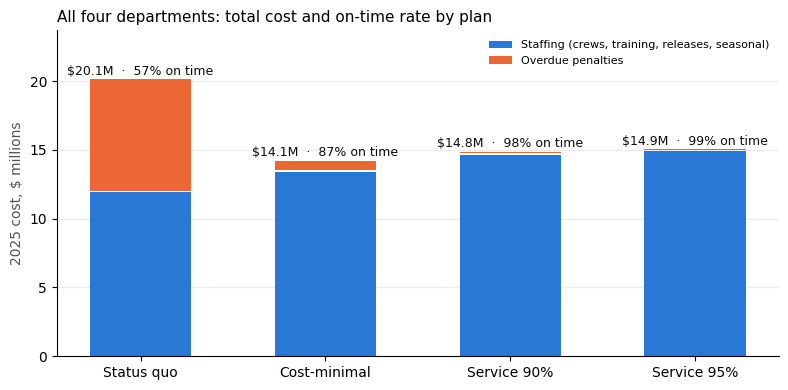

In [7]:
# Chart: total 2025 cost by plan (stacked: staffing vs overdue penalties)
BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(total))
ax.bar(x, total.staff_cost_M, width=0.55, color=BLUE, label="Staffing (crews, training, releases, seasonal)")
ax.bar(x, total.overdue_cost_M, width=0.55, bottom=total.staff_cost_M + 0.08, color=ORANGE, label="Overdue penalties")
for i, (tc, ot) in enumerate(zip(total.total_cost_M, total.on_time_all_depts)):
    ax.text(i, tc + 0.4, f"${tc:.1f}M  ·  {ot:.0%} on time", ha="center", fontsize=9, color=INK)
ax.set_xticks(x, total.index); ax.set_ylabel("2025 cost, $ millions", color=MUTED)
ax.set_ylim(0, total.total_cost_M.max() * 1.18)
ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", alpha=0.25); ax.set_axisbelow(True)
ax.legend(frameon=False, fontsize=8, loc="upper right")
ax.set_title("All four departments: total cost and on-time rate by plan", loc="left", fontsize=11)
plt.tight_layout(); plt.show()

**Decision:** we recommend **Service 90%**. Keeping January's crews all year is the most expensive option, because BTDT, PARK and ISD fall behind and overdue penalties pile up. The cost-minimal plan is cheapest but accepts a lot of late requests at ISD and PARK, since under the brief's numbers a crew costs more per request than a late request does (e.g. ISD ≈ \$139 of crew cost per request vs \$20–\$120 in penalties). Moving to the 90% target costs a little more than the cost-minimal plan and lifts on-time to ~97–98%. Going from 90% to 95% adds cost (mainly ISD and PWDx) for under one point of on-time, so we stop at 90%.

## 6. Recommended plan (Service 90%)

In [8]:
REC = "Service 90%"
MONTHS = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
plan_rows = []
for d in DEPTS:
    plan, sim, cost = plans[(d, REC)]
    for t in range(12):
        plan_rows.append(dict(department=d, month=t + 1, forecast_requests=int(D25[d][t]),
                              fulltime_crews=int(plan["crews"][t]), seasonal_crews=int(plan["seasonal"][t]),
                              crews_starting=int(plan["hires"][t]), crews_released=int(plan["releases"][t]),
                              capacity=int(sim.capacity[t]), backlog_end=round(sim.backlog[t]),
                              on_time_rate=round(sim.on_time_rate[t], 3), utilization=round(sim.utilization[t], 3)))
plan_df = pd.DataFrame(plan_rows)
plan_df.to_csv(os.path.join(DATA_DIR, "staffing_plan_2025.csv"), index=False)

crew_table = plan_df.assign(crews=lambda x: x.fulltime_crews.astype(str)
                            + np.where(x.seasonal_crews > 0, " + " + x.seasonal_crews.astype(str) + "S", ""))
crew_table = crew_table.pivot(index="department", columns="month", values="crews").reindex(DEPTS)
crew_table.columns = MONTHS
print("Crews per month (S = Parks seasonal crews)")
crew_table

Crews per month (S = Parks seasonal crews)


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
department,,,,,,,,,,,,
PWDx,50,50,50,50,50,50,52,60,59,51,51,51
BTDT,18,22,24,25,25,25,25,25,26,26,26,26
PARK,10,10,10,10 + 2S,10 + 8S,10 + 12S,10 + 12S,10 + 10S,10 + 4S,10,10,10
ISD,16,19,19,19,19,21,21,22,22,22,22,22


In [9]:
# Hiring / release / contract calendar (decision month = one month before the change takes effect)
events = []
for d in DEPTS:
    plan = plans[(d, REC)][0]
    for t in range(12):
        if plan["hires"][t]:
            events.append((d, MONTHS[t - 1], f"start hiring {plan['hires'][t]} crew(s) -> working from {MONTHS[t]}"))
        if plan["releases"][t]:
            events.append((d, MONTHS[t - 1], f"give notice to {plan['releases'][t]} crew(s) -> gone from {MONTHS[t]}"))
    s = plan["seasonal"]
    for t in range(12):
        prev = s[t - 1] if t else 0
        if s[t] != prev:
            events.append((d, MONTHS[t], f"seasonal crews {prev} -> {s[t]}"))
pd.DataFrame(events, columns=["department", "decision month", "action"])

,department,decision month,action
0,PWDx,Jun,start hiring 2 crew(s) -> working from Jul
1,PWDx,Jul,start hiring 8 crew(s) -> working from Aug
2,PWDx,Aug,give notice to 1 crew(s) -> gone from Sep
3,PWDx,Sep,give notice to 8 crew(s) -> gone from Oct
4,BTDT,Jan,start hiring 4 crew(s) -> working from Feb
5,BTDT,Feb,start hiring 2 crew(s) -> working from Mar
6,BTDT,Mar,start hiring 1 crew(s) -> working from Apr
7,BTDT,Aug,start hiring 1 crew(s) -> working from Sep
8,PARK,Apr,seasonal crews 0 -> 2
9,PARK,May,seasonal crews 2 -> 8


In [10]:
# Summary of the recommended plan per department
summ = []
for d in DEPTS:
    plan, sim, cost = plans[(d, REC)]
    _, sq_sim, sq_cost = plans[(d, "Status quo")]
    summ.append(dict(dept=d, crews_jan=int(plan["crews"][0]), crews_peak=int((plan["crews"] + plan["seasonal"]).max()),
                     crews_dec=int(plan["crews"][-1]), hires=int(plan["hires"].sum()), releases=int(plan["releases"].sum()),
                     seasonal_crew_months=int(plan["seasonal"].sum()),
                     cost_M=round(cost["total"] / 1e6, 2), status_quo_cost_M=round(sq_cost["total"] / 1e6, 2),
                     on_time=round(1 - sim.overdue.sum() / sim.demand.sum(), 3),
                     status_quo_on_time=round(1 - sq_sim.overdue.sum() / sq_sim.demand.sum(), 3),
                     avg_utilization=round(sim.utilization.mean(), 3)))
summary = pd.DataFrame(summ).set_index("dept")
summary

,crews_jan,crews_peak,crews_dec,hires,releases,seasonal_crew_months,cost_M,status_quo_cost_M,on_time,status_quo_on_time,avg_utilization
dept,,,,,,,,,,,
PWDx,50,60,51,10,9,0,7.22,6.89,0.981,0.864,0.920
BTDT,18,26,26,8,0,0,2.79,7.59,0.980,0.198,0.956
PARK,10,22,10,0,0,48,1.83,2.59,0.984,0.261,0.924
ISD,16,22,22,6,0,0,2.93,3.01,0.964,0.339,0.936


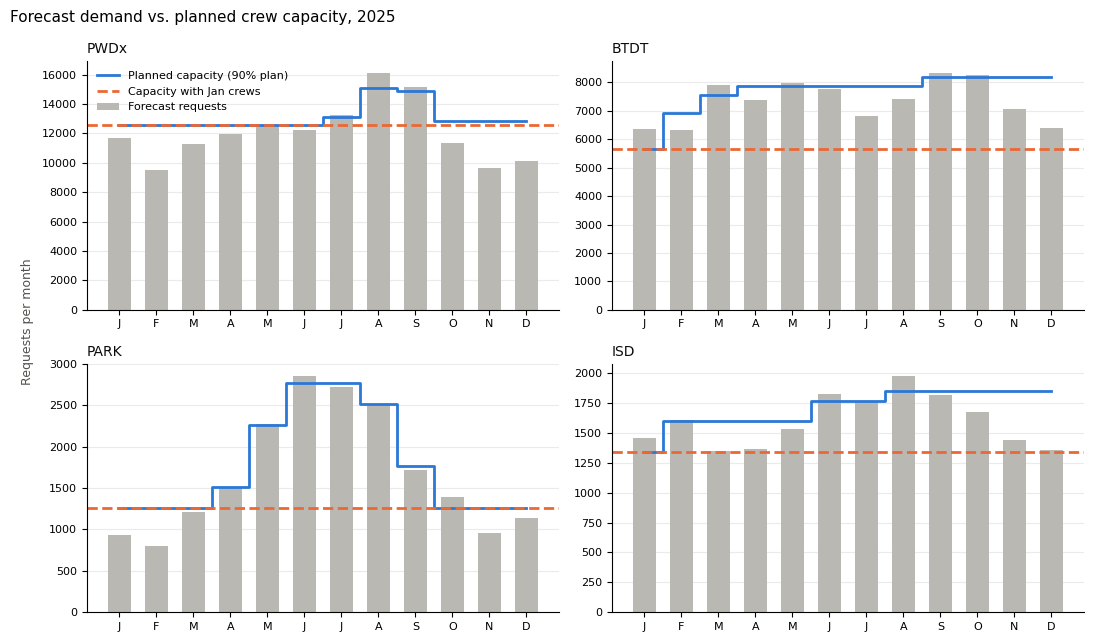

In [11]:
# Chart: monthly demand vs planned capacity (small multiples, one shared unit: requests per month)
GRAY = "#b9b8b3"
fig, axes = plt.subplots(2, 2, figsize=(11, 6.5))
for ax, d in zip(axes.flat, DEPTS):
    plan, sim, _ = plans[(d, REC)]
    sq_cap = PARAMS.loc[d].crews_jan * monthly_capacity(d)
    x = np.arange(1, 13)
    ax.bar(x, D25[d], width=0.6, color=GRAY, label="Forecast requests")
    ax.step(x, sim.capacity, where="mid", color=BLUE, lw=2, label="Planned capacity (90% plan)")
    ax.axhline(sq_cap, color=ORANGE, lw=2, ls="--", label="Capacity with Jan crews")
    ax.set_title(d, loc="left", fontsize=10, color=INK)
    ax.set_xticks(x, [m[0] for m in MONTHS], fontsize=8)
    ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", alpha=0.25); ax.set_axisbelow(True)
    ax.tick_params(axis="y", labelsize=8)
axes[0, 0].legend(frameon=False, fontsize=8, loc="upper left")
fig.supylabel("Requests per month", fontsize=9, color=MUTED)
fig.suptitle("Forecast demand vs. planned crew capacity, 2025", x=0.01, ha="left", fontsize=11)
plt.tight_layout(); plt.show()

## 7. Sensitivity analysis
We **fix the recommended plan** and replay it under different demand. A plan "holds up" if on-time stays high and cost doesn't explode.
- Demand **+20% / −20%** all year (the brief's range)
- **Snowstorm:** February demand +50% for PWDx and BTDT (snow removal, plowing, parking)
- **Heat wave:** July demand +40% for PARK and ISD
- **Lighter workload:** only 90% of requests need crew time (Section 4 suggests reality is closer to this)

We also show what re-optimizing for +20% would cost, i.e. what it takes to adapt if the higher demand were known in advance.

In [12]:
def scenario_demand(name, d):
    D = D25[d].copy()
    if name == "Demand +20%": D *= 1.2
    elif name == "Demand -20%": D *= 0.8
    elif name == "Snowstorm (Feb +50%, PWDx/BTDT)" and d in ("PWDx", "BTDT"): D[1] *= 1.5
    elif name == "Heat wave (Jul +40%, PARK/ISD)" and d in ("PARK", "ISD"): D[6] *= 1.4
    elif name == "Lighter workload (90%)": D *= 0.9
    return D

SCEN = ["Base forecast", "Demand +20%", "Demand -20%", "Snowstorm (Feb +50%, PWDx/BTDT)",
        "Heat wave (Jul +40%, PARK/ISD)", "Lighter workload (90%)"]
rows = []
for sc in SCEN:
    for d in DEPTS:
        D = scenario_demand(sc, d)
        sim, cost = evaluate(D, d, plans[(d, REC)][0])
        rows.append(dict(scenario=sc, dept=d, demand=D.sum(), overdue=sim.overdue.sum(),
                         on_time=1 - sim.overdue.sum() / D.sum(),
                         worst_month_on_time=sim.on_time_rate.min(), total_cost_M=cost["total"] / 1e6,
                         overdue_cost_M=cost["overdue_cost"] / 1e6, backlog_dec=sim.backlog.iloc[-1]))
sens = pd.DataFrame(rows)
sens.round(3).to_csv(os.path.join(DATA_DIR, "sensitivity_results.csv"), index=False)
sens_tot = sens.groupby("scenario", sort=False).agg(total_cost_M=("total_cost_M", "sum"),
                                                    overdue_cost_M=("overdue_cost_M", "sum"),
                                                    demand=("demand", "sum"), overdue=("overdue", "sum"))
sens_tot["on_time_all_depts"] = 1 - sens_tot.overdue / sens_tot.demand
sens_tot = sens_tot[["total_cost_M", "overdue_cost_M", "on_time_all_depts"]].round({"total_cost_M": 2, "overdue_cost_M": 2, "on_time_all_depts": 3})
sens_tot

,total_cost_M,overdue_cost_M,on_time_all_depts
scenario,,,
Base forecast,14.77,0.11,0.980
Demand +20%,23.20,8.54,0.345
Demand -20%,14.66,0.00,1.000
"Snowstorm (Feb +50%, PWDx/BTDT)",15.28,0.62,0.889
"Heat wave (Jul +40%, PARK/ISD)",14.95,0.29,0.947
Lighter workload (90%),14.66,0.00,1.000


In [13]:
sens.pivot(index="scenario", columns="dept", values="on_time").reindex(SCEN)[DEPTS].round(3)

dept,PWDx,BTDT,PARK,ISD
scenario,,,,
Base forecast,0.981,0.980,0.984,0.964
Demand +20%,0.431,0.206,0.411,0.266
Demand -20%,1.000,1.000,1.000,1.000
"Snowstorm (Feb +50%, PWDx/BTDT)",0.968,0.724,0.984,0.964
"Heat wave (Jul +40%, PARK/ISD)",0.981,0.980,0.700,0.810
Lighter workload (90%),1.000,0.999,1.000,1.000


In [14]:
# If +20% demand were known in advance: re-optimized plan vs. sticking with the base plan
rows = []
for d in DEPTS:
    D = scenario_demand("Demand +20%", d)
    re = optimize(D, d, min_on_time=0.90)
    s_re, c_re = evaluate(D, d, re)
    s_fx, c_fx = evaluate(D, d, plans[(d, REC)][0])
    rows.append(dict(dept=d, fixed_plan_cost_M=c_fx["total"] / 1e6, fixed_plan_on_time=1 - s_fx.overdue.sum() / D.sum(),
                     reoptimized_cost_M=c_re["total"] / 1e6, reoptimized_on_time=1 - s_re.overdue.sum() / D.sum(),
                     extra_crews_at_peak=int((re["crews"] + re["seasonal"]).max()
                                             - (plans[(d, REC)][0]["crews"] + plans[(d, REC)][0]["seasonal"]).max())))
adapt = pd.DataFrame(rows).set_index("dept").round(3)
adapt

,fixed_plan_cost_M,fixed_plan_on_time,reoptimized_cost_M,reoptimized_on_time,extra_crews_at_peak
dept,,,,,
PWDx,10.683,0.431,8.439,0.969,11
BTDT,6.314,0.206,3.406,0.971,5
PARK,2.633,0.411,2.167,0.975,5
ISD,3.567,0.266,3.659,0.959,4


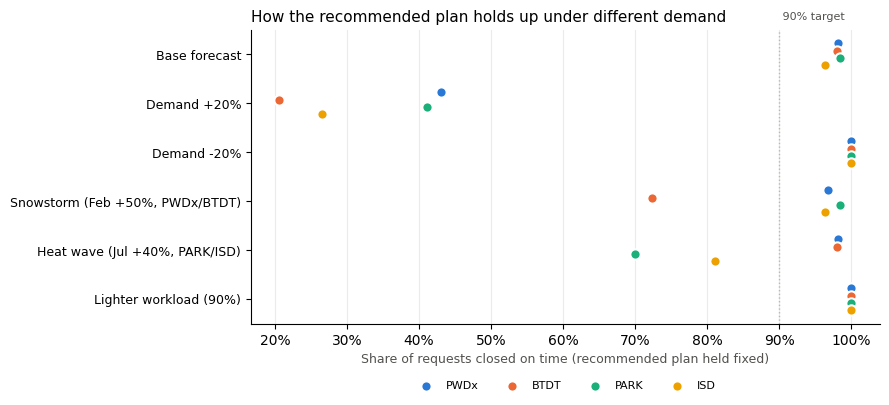

In [15]:
# Chart: on-time rate of the fixed plan under each scenario
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]   # fixed categorical order, one hue per department
pv = sens.pivot(index="scenario", columns="dept", values="on_time").reindex(SCEN)[DEPTS]
fig, ax = plt.subplots(figsize=(9, 4.2))
y = np.arange(len(SCEN))
for i, d in enumerate(DEPTS):
    ax.scatter(pv[d], y + (i - 1.5) * 0.15, s=55, color=CAT[i], label=d, edgecolor="white", linewidth=1.5, zorder=3)
ax.set_yticks(y, SCEN, fontsize=9); ax.invert_yaxis()
ax.set_xlabel("Share of requests closed on time (recommended plan held fixed)", fontsize=9, color=MUTED)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.axvline(0.9, color=GRAY, lw=1, ls=":"); ax.text(0.9, -0.7, " 90% target", fontsize=8, color=MUTED)
ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="x", alpha=0.25); ax.set_axisbelow(True)
ax.legend(frameon=False, fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.16))
ax.set_title("How the recommended plan holds up under different demand", loc="left", fontsize=11)
plt.tight_layout(); plt.show()

## 8. Key findings
See the cell below: it prints the numbers used in the report text, so the report always matches the model.

In [16]:
rec_tot, sq_tot, min_tot = total.loc[REC], total.loc["Status quo"], total.loc["Cost-minimal"]
print(f"Recommended plan ({REC}): ${rec_tot.total_cost_M:.2f}M, on-time {rec_tot.on_time_all_depts:.1%}")
print(f"Status quo (Jan crews all year): ${sq_tot.total_cost_M:.2f}M, on-time {sq_tot.on_time_all_depts:.1%}")
print(f"Cost-minimal: ${min_tot.total_cost_M:.2f}M, on-time {min_tot.on_time_all_depts:.1%}")
print()
for d in DEPTS:
    r = summary.loc[d]
    print(f"{d}: {int(r.crews_jan)} -> peak {int(r.crews_peak)} -> Dec {int(r.crews_dec)} crews | hires {int(r.hires)}, "
          f"releases {int(r.releases)}, seasonal crew-months {int(r.seasonal_crew_months)} | ${r.cost_M}M vs status quo ${r.status_quo_cost_M}M | "
          f"on-time {r.on_time:.1%} (status quo {r.status_quo_on_time:.1%})")
print()
for s in SCEN[1:]:
    print(f"{s}: on-time {sens_tot.loc[s, 'on_time_all_depts']:.1%}, cost ${sens_tot.loc[s, 'total_cost_M']:.2f}M")

Recommended plan (Service 90%): $14.77M, on-time 98.0%
Status quo (Jan crews all year): $20.07M, on-time 56.7%
Cost-minimal: $14.12M, on-time 87.2%

PWDx: 50 -> peak 60 -> Dec 51 crews | hires 10, releases 9, seasonal crew-months 0 | $7.22M vs status quo $6.89M | on-time 98.1% (status quo 86.4%)
BTDT: 18 -> peak 26 -> Dec 26 crews | hires 8, releases 0, seasonal crew-months 0 | $2.79M vs status quo $7.59M | on-time 98.0% (status quo 19.8%)
PARK: 10 -> peak 22 -> Dec 10 crews | hires 0, releases 0, seasonal crew-months 48 | $1.83M vs status quo $2.59M | on-time 98.4% (status quo 26.1%)
ISD: 16 -> peak 22 -> Dec 22 crews | hires 6, releases 0, seasonal crew-months 0 | $2.93M vs status quo $3.01M | on-time 96.4% (status quo 33.9%)

Demand +20%: on-time 34.5%, cost $23.20M
Demand -20%: on-time 100.0%, cost $14.66M
Snowstorm (Feb +50%, PWDx/BTDT): on-time 88.9%, cost $15.28M
Heat wave (Jul +40%, PARK/ISD): on-time 94.7%, cost $14.95M
Lighter workload (90%): on-time 100.0%, cost $14.66M
